# Weekly Meal Demand Forecasting for a Food Delivery Network

**Business problem.** A meal-delivery company runs fulfilment centres across many cities. Raw materials are perishable and are ordered ahead of time, so every centre has to decide how much of each ingredient to buy before it knows the week's orders. Ordering too much wastes food; ordering too little loses sales. This notebook forecasts weekly orders for every (centre, meal) pair and then asks the question the business actually cares about: *how much waste and how many stockouts does a better forecast avoid?*

**Data.** [Food Demand Forecasting (Kaggle)](https://www.kaggle.com/datasets/kannanaikkal/food-demand-forecasting): about 456k weekly rows across 77 fulfilment centres and 51 meals over 145 weeks, with price, discount and promotion columns.

**What the notebook does**

| Step | Section | Tooling |
|---|---|---|
| Load, validate, profile | 1–2 | PySpark |
| Exploratory analysis | 3 | PySpark aggregations, matplotlib |
| Leakage-safe feature engineering | 4 | PySpark window functions |
| Rolling-origin backtest of baselines vs a global gradient-boosted model | 5–6 | LightGBM |
| Comparison with a per-series statistical model | 7 | statsmodels (exponential smoothing) |
| Error analysis | 8 | pandas |
| Business impact: waste vs stockouts, quantile ordering policy | 9 | LightGBM quantile regression |
| Findings, limitations, recommendations | 10–11 | |

**Forecast setting.** Each forecast is made `HORIZON` weeks before the target week, which stands in for the purchasing lead time. Every feature for target week *t* uses only information available at week *t − HORIZON*, apart from that week's planned price and promotions, which the business sets in advance.

## 0. Setup

**Where to run it:** Google Colab is the easiest option: upload the three CSVs to a `data/` folder and run the install cell. Databricks Free Edition also works; set `DATA_DIR` to your Volume path. Running locally needs Java 17+ for Spark.

Download `train.csv`, `fulfilment_center_info.csv` and `meal_info.csv` from Kaggle into `DATA_DIR`.

In [22]:
# Uncomment on Colab / a fresh environment:
# !pip install -q pyspark lightgbm statsmodels pyarrow

In [23]:

import os, shutil, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import lightgbm as lgb
from pyspark.sql import SparkSession, Window, functions as F, types as T

warnings.filterwarnings("ignore", category=FutureWarning)

# ---- configuration -------------------------------------------------------
DATA_DIR   = os.environ.get("FOOD_DATA_DIR", "data")      # folder with the 3 CSVs
OUTPUT_DIR = os.environ.get("FOOD_OUTPUT_DIR", "outputs")
HORIZON    = 2      # weeks between making the forecast and the target week (purchasing lead time)
TEST_LEN   = 10     # weeks per backtest fold
N_FOLDS    = 3      # rolling-origin folds
SEED       = 42

# Business cost assumptions used in section 9. These are ASSUMPTIONS, not data:
# change them to match the real business before quoting any money figure.
COST_OVER  = 1.0    # cost of one unit ordered but not sold (wasted ingredients)
COST_UNDER = 3.0    # cost of one unit of demand not met (lost margin + customer goodwill)

os.makedirs(OUTPUT_DIR, exist_ok=True)
np.random.seed(SEED)

# Chart style: one axis per chart, thin marks, recessive grid, fixed categorical order.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 1.6,
    "axes.axisbelow": True,   # grid behind bars
})

In [24]:
# Spark session. On Databricks a session already exists and its config is managed for you.
if "DATABRICKS_RUNTIME_VERSION" in os.environ:
    spark = SparkSession.builder.getOrCreate()
else:
    spark = (SparkSession.builder
             .appName("food-demand-forecasting")
             .master("local[*]")
             .config("spark.driver.memory", "4g")
             .config("spark.sql.shuffle.partitions", "16")   # default 200 is far too many for one machine
             .config("spark.sql.session.timeZone", "UTC")
             .config("spark.ui.showConsoleProgress", "false")
             .getOrCreate())
    spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

Spark 4.2.0


## 1. Load the data with explicit schemas

Explicit schemas instead of `inferSchema`: inference needs an extra pass over the data, and it silently turns an ID column into a float if one bad value appears. Declaring types up front makes a malformed file fail loudly.

In [25]:
train_schema = T.StructType([
    T.StructField("id", T.LongType()),
    T.StructField("week", T.IntegerType()),
    T.StructField("center_id", T.IntegerType()),
    T.StructField("meal_id", T.IntegerType()),
    T.StructField("checkout_price", T.DoubleType()),
    T.StructField("base_price", T.DoubleType()),
    T.StructField("emailer_for_promotion", T.IntegerType()),
    T.StructField("homepage_featured", T.IntegerType()),
    T.StructField("num_orders", T.IntegerType()),
])
center_schema = T.StructType([
    T.StructField("center_id", T.IntegerType()),
    T.StructField("city_code", T.IntegerType()),
    T.StructField("region_code", T.IntegerType()),
    T.StructField("center_type", T.StringType()),
    T.StructField("op_area", T.DoubleType()),
])
meal_schema = T.StructType([
    T.StructField("meal_id", T.IntegerType()),
    T.StructField("category", T.StringType()),
    T.StructField("cuisine", T.StringType()),
])

def read_csv(name, schema):
    path = os.path.join(DATA_DIR, name)
    return spark.read.csv(path, header=True, schema=schema, mode="FAILFAST")

orders  = read_csv("train.csv", train_schema)
centers = read_csv("fulfilment_center_info.csv", center_schema)
meals   = read_csv("meal_info.csv", meal_schema)

df = (orders
      .join(F.broadcast(centers), "center_id", "left")   # small dimension tables -> broadcast join, no shuffle
      .join(F.broadcast(meals), "meal_id", "left")
      .cache())

print(f"orders rows: {df.count():,}")
df.show(5)

orders rows: 456,548
+-------+---------+-------+----+--------------+----------+---------------------+-----------------+----------+---------+-----------+-----------+-------+---------+-------+
|meal_id|center_id|     id|week|checkout_price|base_price|emailer_for_promotion|homepage_featured|num_orders|city_code|region_code|center_type|op_area| category|cuisine|
+-------+---------+-------+----+--------------+----------+---------------------+-----------------+----------+---------+-----------+-----------+-------+---------+-------+
|   1885|       55|1379560|   1|        136.83|    152.29|                    0|                0|       177|      647|         56|     TYPE_C|    2.0|Beverages|   Thai|
|   1993|       55|1466964|   1|        136.83|    135.83|                    0|                0|       270|      647|         56|     TYPE_C|    2.0|Beverages|   Thai|
|   2539|       55|1346989|   1|        134.86|    135.86|                    0|                0|       189|      647|         5

## 2. Data quality checks

Every check should come back clean or be explained before modelling. The one that matters most for forecasting is the last: **calendar gaps**. A missing week could mean the meal wasn't offered, or that zero orders weren't recorded. That decides whether lag features are computed correctly (section 4).

In [26]:
key = ["center_id", "meal_id", "week"]

null_counts = df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).toPandas().T
null_counts.columns = ["nulls"]

checks = {
    "duplicate (centre, meal, week) rows": df.groupBy(key).count().where("count > 1").count(),
    "unmatched centre_id (no centre info)": df.where(F.col("center_type").isNull()).count(),
    "unmatched meal_id (no meal info)": df.where(F.col("category").isNull()).count(),
    "non-positive checkout_price": df.where("checkout_price <= 0").count(),
    "non-positive num_orders": df.where("num_orders <= 0").count(),
    "checkout_price above base_price (price raised)": df.where("checkout_price > base_price * 1.001").count(),
}
for k, v in checks.items():
    print(f"{k:<48} {v:>8,}")
print("\nNulls per column (non-zero only):")
print(null_counts[null_counts.nulls > 0] if (null_counts.nulls > 0).any() else "  none")

duplicate (centre, meal, week) rows                     0
unmatched centre_id (no centre info)                    0
unmatched meal_id (no meal info)                        0
non-positive checkout_price                             0
non-positive num_orders                                 0
checkout_price above base_price (price raised)    115,774

Nulls per column (non-zero only):
  none


In [27]:
series_stats = (df.groupBy("center_id", "meal_id")
                  .agg(F.min("week").alias("first_week"), F.max("week").alias("last_week"),
                       F.count("*").alias("n_weeks"))
                  .withColumn("span", F.col("last_week") - F.col("first_week") + 1)
                  .withColumn("missing_weeks", F.col("span") - F.col("n_weeks")))

s = series_stats.toPandas()
MAX_WEEK = int(df.agg(F.max("week")).first()[0])
MIN_WEEK = int(df.agg(F.min("week")).first()[0])
print(f"weeks {MIN_WEEK}..{MAX_WEEK} | series (centre x meal): {len(s):,}")
print(f"series with at least one gap: {(s.missing_weeks > 0).mean():.1%}")
print(f"share of in-span weeks missing: {s.missing_weeks.sum() / s.span.sum():.2%}")
print(f"series that start after week {MIN_WEEK}: {(s.first_week > MIN_WEEK).mean():.1%}  (new menu items / new centres)")
print(f"series that stop before week {MAX_WEEK}: {(s.last_week < MAX_WEEK).mean():.1%}  (discontinued)")

weeks 1..145 | series (centre x meal): 3,597
series with at least one gap: 59.2%
share of in-span weeks missing: 8.16%
series that start after week 1: 18.8%  (new menu items / new centres)
series that stop before week 145: 9.1%  (discontinued)


**Decision on gaps.** Missing weeks are treated as *unknown*, not as zero demand. The data doesn't say which it is, and filling with zeros would teach the model that demand regularly collapses to nothing. All lag and rolling features below use **range-based windows over the week number**, so a gap stays a gap instead of shifting the next row into its place. (A row-based `lag(1)` after a missing week silently returns the value from two weeks ago.)

## 3. Exploratory analysis

All aggregation runs in Spark; only the small summarised results come back to pandas for plotting.

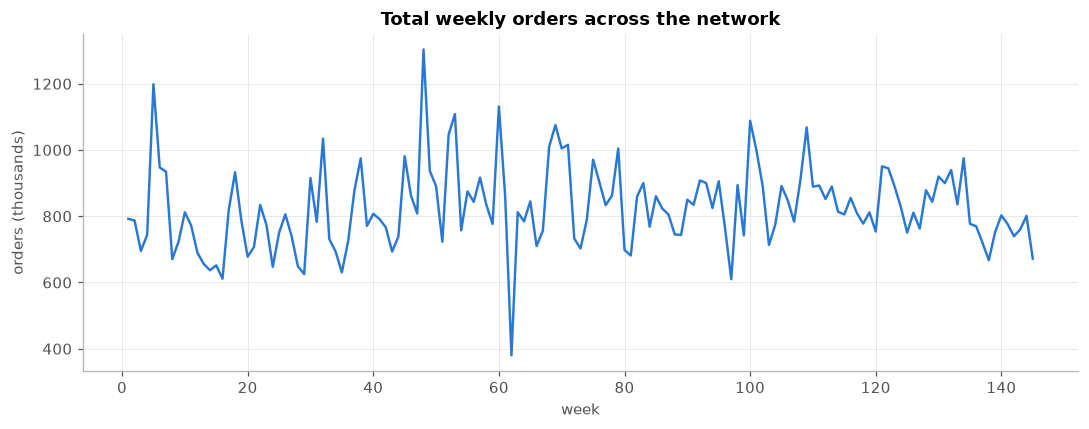

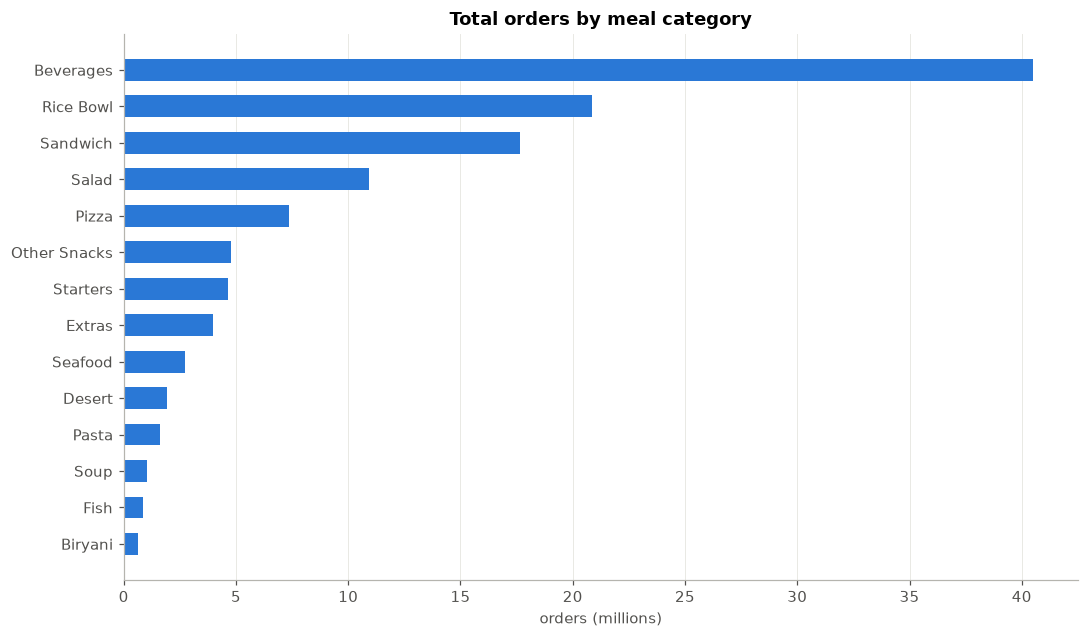

In [28]:
weekly = df.groupBy("week").agg(F.sum("num_orders").alias("orders")).orderBy("week").toPandas()

fig, ax = plt.subplots()
ax.plot(weekly.week, weekly.orders / 1e3, color=PALETTE[0])
ax.set_title("Total weekly orders across the network")
ax.set_xlabel("week"); ax.set_ylabel("orders (thousands)")
plt.tight_layout(); plt.show()

by_cat = (df.groupBy("category").agg(F.sum("num_orders").alias("orders"))
            .orderBy("orders").toPandas())
fig, ax = plt.subplots(figsize=(10, 0.35 * len(by_cat) + 1))
ax.barh(by_cat.category, by_cat.orders / 1e6, color=PALETTE[0], height=0.6)
ax.set_title("Total orders by meal category"); ax.set_xlabel("orders (millions)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### Promotion and discount effects, measured within series

Comparing raw average orders in promoted and non-promoted weeks is misleading: promotions aren't spread evenly across meals, so the comparison mixes up *which meals get promoted* with *what promotion does*. Instead each week is divided by the same series' own median non-promoted demand, so every meal is compared only with itself.

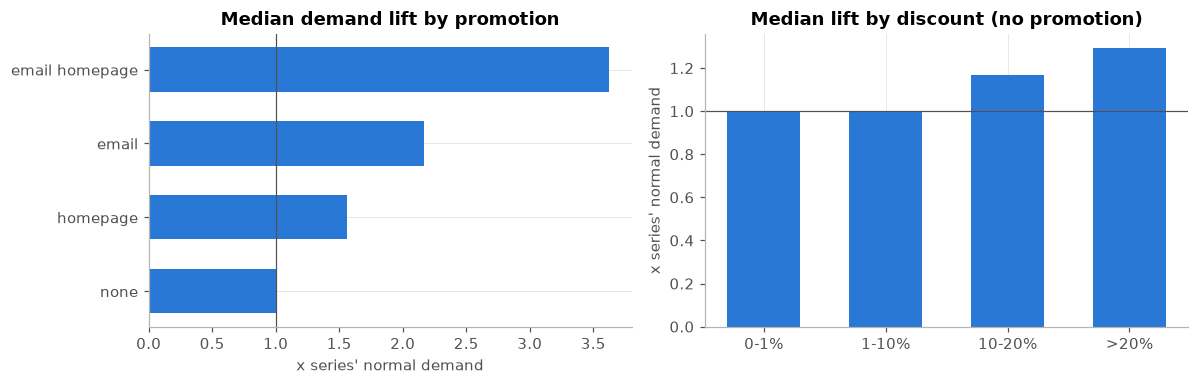

,promo_state,median_lift,weeks
0,none,1.000000,388874
1,homepage,1.562500,30624
2,email,2.170279,17819
3,email homepage,3.620370,19231


,median_lift,weeks
discount_bucket,,
0-1%,1.000000,317803
1-10%,1.000000,8322
10-20%,1.167702,35984
>20%,1.292683,26765


In [29]:
df = df.withColumn("discount_pct", (F.col("base_price") - F.col("checkout_price")) / F.col("base_price"))

baseline = (df.where("emailer_for_promotion = 0 AND homepage_featured = 0")
              .groupBy("center_id", "meal_id")
              .agg(F.percentile_approx("num_orders", 0.5).alias("baseline_orders")))

lift = (df.join(baseline, ["center_id", "meal_id"])
          .withColumn("lift", F.col("num_orders") / F.col("baseline_orders"))
          .withColumn("promo_state", F.concat(
              F.when(F.col("emailer_for_promotion") == 1, F.lit("email ")).otherwise(F.lit("")),
              F.when(F.col("homepage_featured") == 1, F.lit("homepage")).otherwise(F.lit(""))))
          .withColumn("promo_state", F.when(F.col("promo_state") == "", "none").otherwise(F.trim("promo_state")))
          .withColumn("discount_bucket", F.when(F.col("discount_pct") <= 0.01, "0-1%")
                                          .when(F.col("discount_pct") <= 0.10, "1-10%")
                                          .when(F.col("discount_pct") <= 0.20, "10-20%")
                                          .otherwise(">20%")))

promo_lift = (lift.groupBy("promo_state")
                  .agg(F.percentile_approx("lift", 0.5).alias("median_lift"), F.count("*").alias("weeks"))
                  .orderBy("median_lift").toPandas())
disc_lift = (lift.where("emailer_for_promotion = 0 AND homepage_featured = 0")   # isolate price effect
                 .groupBy("discount_bucket")
                 .agg(F.percentile_approx("lift", 0.5).alias("median_lift"), F.count("*").alias("weeks"))
                 .toPandas().set_index("discount_bucket").reindex(["0-1%", "1-10%", "10-20%", ">20%"]).dropna())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].barh(promo_lift.promo_state, promo_lift.median_lift, color=PALETTE[0], height=0.6)
axes[0].axvline(1, color="#52514e", lw=0.8)
axes[0].set_title("Median demand lift by promotion"); axes[0].set_xlabel("x series' normal demand")
axes[1].bar(disc_lift.index, disc_lift.median_lift, color=PALETTE[0], width=0.6)
axes[1].axhline(1, color="#52514e", lw=0.8)
axes[1].set_title("Median lift by discount (no promotion)"); axes[1].set_ylabel("x series' normal demand")
for a in axes: a.grid(axis="y" if a is axes[1] else "x")
plt.tight_layout(); plt.show()
display(promo_lift, disc_lift)

## 4. Feature engineering in PySpark (leakage-safe)

Rule: for target week *t*, demand-based features may only see weeks ≤ *t − HORIZON*. Planned price and promotion flags for week *t* are allowed, because the business sets them before the week starts.

| Group | Features | Why |
|---|---|---|
| Lags | demand at *t−H*, *t−H−1*, *t−H−2*, *t−H−3*, and *t−52* | recent level and annual seasonality |
| Rolling stats | mean / std / count over the 4, 8 and 13 weeks ending at *t−H* | smoothed level, volatility, data availability |
| Expanding mean | series mean over all history up to *t−H* | stable level for sparse series |
| Hierarchy | network-wide demand for the meal at *t−H*; centre total at *t−H* | borrow strength from related series |
| Price | discount %, price vs series' recent average, price vs same meal at other centres this week | elasticity and relative price |
| Promotion | emailer, homepage, and whether each ran the previous week | lift and post-promotion dip |
| Calendar | week of year (sin/cos) | seasonality |
| Static | centre type, area, city, region, meal category, cuisine, ids | cross-sectional differences |

The target is `log1p(num_orders)`. Demand is heavily right-skewed, and on the raw scale a few huge series would dominate the loss.

In [30]:
H = HORIZON
series_w = Window.partitionBy("center_id", "meal_id").orderBy("week")

def at_lag(col, k, w=series_w):
    # value exactly k weeks earlier; null if that week is missing (range window = calendar-aware)
    return F.max(col).over(w.rangeBetween(-k, -k))

def trailing(agg, col, n, w=series_w):
    # aggregate over the n weeks ending at t-H, e.g. weeks [t-H-n+1, t-H]
    return agg(col).over(w.rangeBetween(-(H + n - 1), -H))

feat = df
# --- demand lags (all >= H, so known at forecast time)
for k in [H, H + 1, H + 2, H + 3]:
    feat = feat.withColumn(f"lag_{k}", at_lag("num_orders", k))
if 52 >= H:
    feat = feat.withColumn("lag_52", at_lag("num_orders", 52))

# --- rolling statistics
for n in [4, 8, 13]:
    feat = (feat.withColumn(f"rmean_{n}", trailing(F.avg, "num_orders", n))
                .withColumn(f"rstd_{n}", trailing(F.stddev, "num_orders", n))
                .withColumn(f"rcount_{n}", trailing(F.count, "num_orders", n)))
feat = feat.withColumn("trend_4_13", F.col("rmean_4") / F.col("rmean_13"))

# --- expanding mean of the series up to t-H
feat = feat.withColumn("hist_mean", F.avg("num_orders").over(series_w.rangeBetween(Window.unboundedPreceding, -H)))

# --- hierarchy: aggregate, then lag the aggregate
meal_week = df.groupBy("meal_id", "week").agg(F.sum("num_orders").alias("meal_total"))
meal_week = meal_week.withColumn(
    "meal_total_lag", at_lag("meal_total", H, Window.partitionBy("meal_id").orderBy("week"))).drop("meal_total")
center_week = df.groupBy("center_id", "week").agg(F.sum("num_orders").alias("center_total"))
center_week = center_week.withColumn(
    "center_total_lag", at_lag("center_total", H, Window.partitionBy("center_id").orderBy("week"))).drop("center_total")
feat = feat.join(meal_week, ["meal_id", "week"], "left").join(center_week, ["center_id", "week"], "left")

# --- price features (planned prices for week t are known in advance)
feat = (feat
    .withColumn("price_vs_recent", F.col("checkout_price") / trailing(F.avg, "checkout_price", 8))
    .withColumn("price_change_1w", F.col("checkout_price") / at_lag("checkout_price", 1) - 1)
    .withColumn("price_vs_network", F.col("checkout_price") /
                F.avg("checkout_price").over(Window.partitionBy("meal_id", "week"))))

# --- promotion carry-over (last week's plan is known)
feat = (feat.withColumn("emailer_prev", at_lag("emailer_for_promotion", 1))
            .withColumn("homepage_prev", at_lag("homepage_featured", 1)))

# --- calendar
woy = ((F.col("week") - 1) % 52) + 1
feat = (feat.withColumn("woy_sin", F.sin(2 * np.pi * woy / 52))
            .withColumn("woy_cos", F.cos(2 * np.pi * woy / 52)))

# --- target
feat = feat.withColumn("y", F.log1p("num_orders"))

feat_path = os.path.join(OUTPUT_DIR, "features.parquet")
# Materialise once: the window plan is expensive to recompute. Collected to pandas and saved with
# pyarrow rather than Spark's writer, which on Windows needs Hadoop's winutils.exe (HADOOP_HOME).
features_pdf = feat.toPandas()
if os.path.isdir(feat_path):   # left behind by an earlier Spark write, which saves parquet as a folder
    shutil.rmtree(feat_path)
features_pdf.to_parquet(feat_path, index=False)
print(f"feature table: {len(features_pdf):,} rows x {features_pdf.shape[1]} columns")

feature table: 456,548 rows x 42 columns


**Sanity check for leakage.** If a lag accidentally used the current week, `lag_H` would line up exactly with `num_orders`. The check below recomputes one lag in pandas the slow, obvious way and confirms Spark agrees.

In [31]:
pdf = features_pdf.copy()   # ~456k rows fits comfortably in memory; Spark did the heavy windowing

probe = pdf[["center_id", "meal_id", "week", "num_orders", f"lag_{H}"]].copy()
manual = probe[["center_id", "meal_id", "week", "num_orders"]].rename(columns={"num_orders": "manual_lag"})
manual["week"] += H
probe = probe.merge(manual, on=["center_id", "meal_id", "week"], how="left")
mismatch = ~((probe[f"lag_{H}"] == probe.manual_lag) | (probe[f"lag_{H}"].isna() & probe.manual_lag.isna()))
print(f"lag_{H} mismatches vs manual calendar lag: {mismatch.sum()}")
assert mismatch.sum() == 0
print(f"corr(lag_{H}, num_orders) = {pdf[f'lag_{H}'].corr(pdf.num_orders):.3f}  (high but < 1 is expected)")

lag_2 mismatches vs manual calendar lag: 0
corr(lag_2, num_orders) = 0.583  (high but < 1 is expected)


## 5. Backtesting design: rolling-origin cross-validation

A random train/test split would let the model train on week 120 and be tested on week 100, which tells you nothing about forecasting the future. Instead:

* The last `N_FOLDS × TEST_LEN` weeks are split into consecutive test blocks.
* For each block the model trains on **expanding history** that ends `HORIZON` weeks before the block starts. That gap matters: when the first test week is forecast, the most recent `HORIZON` weeks of actuals don't exist yet.
* Early stopping uses an **inner validation slice** (the last 8 weeks of the training window), never the test block.

fold 0: train weeks <= 114 | gap 2 | test weeks 116..125
fold 1: train weeks <= 124 | gap 2 | test weeks 126..135
fold 2: train weeks <= 134 | gap 2 | test weeks 136..145


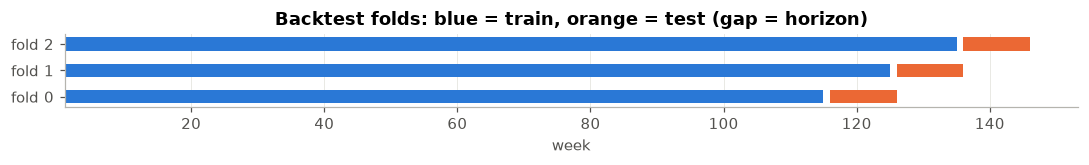

In [32]:
fold_starts = [MAX_WEEK - (N_FOLDS - i) * TEST_LEN + 1 for i in range(N_FOLDS)]
folds = []
for start in fold_starts:
    folds.append(dict(train_end=start - H, test_start=start, test_end=start + TEST_LEN - 1))
for i, f in enumerate(folds):
    print(f"fold {i}: train weeks <= {f['train_end']:>3} | gap {H} | test weeks {f['test_start']}..{f['test_end']}")

# timeline picture
fig, ax = plt.subplots(figsize=(10, 1.6))
for i, f in enumerate(folds):
    ax.barh(i, f["train_end"] - MIN_WEEK + 1, left=MIN_WEEK, color=PALETTE[0], height=0.5)
    ax.barh(i, TEST_LEN, left=f["test_start"], color=PALETTE[1], height=0.5)
ax.set_yticks(range(len(folds))); ax.set_yticklabels([f"fold {i}" for i in range(len(folds))])
ax.set_xlabel("week"); ax.set_title("Backtest folds: blue = train, orange = test (gap = horizon)")
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()

In [33]:
CAT_COLS = ["center_id", "meal_id", "city_code", "region_code", "center_type", "category", "cuisine"]
NUM_COLS = [c for c in pdf.columns if c.startswith(("lag_", "rmean_", "rstd_", "rcount_"))] + [
    "trend_4_13", "hist_mean", "meal_total_lag", "center_total_lag",
    "checkout_price", "base_price", "discount_pct", "price_vs_recent", "price_change_1w", "price_vs_network",
    "emailer_for_promotion", "homepage_featured", "emailer_prev", "homepage_prev",
    "op_area", "woy_sin", "woy_cos"]
FEATURES = CAT_COLS + NUM_COLS

for c in CAT_COLS:
    pdf[c] = pdf[c].astype("category")
pdf = pdf.sort_values(["week", "center_id", "meal_id"]).reset_index(drop=True)

def wape(y, f):  return np.abs(y - f).sum() / y.sum()
def bias(y, f):  return (f - y).sum() / y.sum()            # >0 means over-forecasting
def rmsle(y, f): return np.sqrt(np.mean((np.log1p(np.maximum(f, 0)) - np.log1p(y)) ** 2))

def score(name, y, f, fold):
    return dict(model=name, fold=fold, WAPE=wape(y, f), bias=bias(y, f), RMSLE=rmsle(y, f))

## 6. Models

1. **Naive:** demand at *t − H*, the "same as the last known week" rule a planner might use.
2. **Moving average (4 weeks):** the trailing 4-week mean ending at *t − H*.
3. **LightGBM global model:** one gradient-boosted model across all series, trained on log demand.

Both baselines fall back to the series' historical mean (then to the global median) when a lag is missing, so every model is scored on **exactly the same rows**.

**Back-transform bias.** A model trained on `log1p(y)` with squared error predicts the mean of the *log*, and `expm1` of that is below the mean of *y*. Left alone, forecasts run systematically low. A single multiplicative correction factor, estimated on the inner validation slice, fixes the total. This is a simple version of Duan's smearing estimator.

In [34]:
LGB_PARAMS = dict(objective="regression", learning_rate=0.05, num_leaves=63, min_data_in_leaf=50,
                  feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0,
                  verbose=-1, seed=SEED)

def fallback(primary, frame):
    glob = frame["num_orders"].median()
    return primary.fillna(frame["hist_mean"]).fillna(glob)

def fit_lgb(train, params, inner_val_weeks=8, max_rounds=3000):
    cut = train.week.max() - inner_val_weeks
    tr, va = train[train.week <= cut], train[train.week > cut]
    dtr = lgb.Dataset(tr[FEATURES], tr.y, categorical_feature=CAT_COLS, free_raw_data=False)
    dva = lgb.Dataset(va[FEATURES], va.y, reference=dtr)
    m = lgb.train(params, dtr, max_rounds, valid_sets=[dva],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
    best = m.best_iteration
    # smearing factor: how much the back-transformed validation forecast under-shoots in total
    smear = va.num_orders.sum() / np.expm1(m.predict(va[FEATURES], num_iteration=best)).sum()
    # refit on the full training window with the chosen number of rounds
    full = lgb.train(params, lgb.Dataset(train[FEATURES], train.y, categorical_feature=CAT_COLS), best)
    return full, best, smear

results, preds = [], []
for i, f in enumerate(folds):
    t0 = time.time()
    train = pdf[pdf.week <= f["train_end"]]
    test  = pdf[(pdf.week >= f["test_start"]) & (pdf.week <= f["test_end"])].copy()

    test["pred_naive"] = fallback(test[f"lag_{H}"], train)
    test["pred_ma4"]   = fallback(test["rmean_4"], train)
    model, best_iter, smear = fit_lgb(train, LGB_PARAMS)
    raw = np.expm1(model.predict(test[FEATURES]))
    test["pred_lgb_raw"] = raw
    test["pred_lgb"]     = raw * smear
    test["fold"] = i

    for name in ["naive", "ma4", "lgb_raw", "lgb"]:
        results.append(score(name, test.num_orders.values, test[f"pred_{name}"].values, i))
    preds.append(test)
    print(f"fold {i}: {len(train):,} train rows, {len(test):,} test rows, "
          f"{best_iter} rounds, smearing x{smear:.3f}, {time.time() - t0:.0f}s")

res = pd.DataFrame(results)
preds = pd.concat(preds, ignore_index=True)
last_model = model

fold 0: 354,787 train rows, 32,834 test rows, 84 rounds, smearing x1.099, 12s
fold 1: 387,660 train rows, 32,820 test rows, 425 rounds, smearing x1.037, 27s
fold 2: 420,466 train rows, 32,821 test rows, 214 rounds, smearing x1.147, 20s


fold,0,1,2
model,,,
naive,0.5234,0.5740,0.4537
ma4,0.4736,0.5021,0.3982
lgb_raw,0.2768,0.2931,0.2733
lgb,0.2766,0.2898,0.2814


WAPE            bias           RMSLE        
           mean     std    mean     std    mean     std
model                                                  
naive    0.5171  0.0604  0.0257  0.0295  0.8598  0.0406
ma4      0.4579  0.0537  0.0166  0.0407  0.7189  0.0368
lgb_raw  0.2811  0.0106 -0.0915  0.0227  0.4774  0.0092
lgb      0.2826  0.0066 -0.0050  0.0738  0.4867  0.0171

LightGBM vs 4-week moving average: WAPE 0.458 -> 0.283 (38.3% relative reduction)


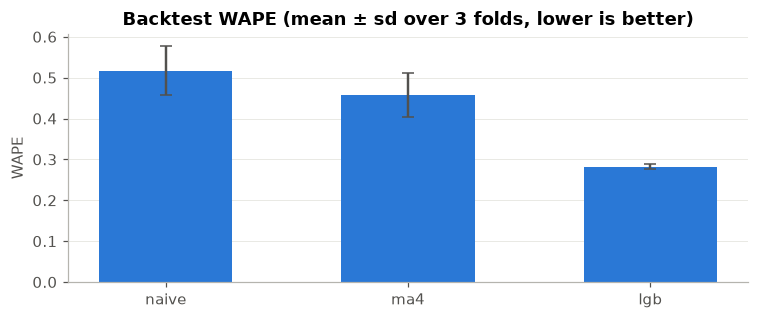

In [35]:
summary = (res.groupby("model")[["WAPE", "bias", "RMSLE"]].agg(["mean", "std"]).round(4)
             .reindex(["naive", "ma4", "lgb_raw", "lgb"]))
display(res.pivot(index="model", columns="fold", values="WAPE").reindex(summary.index).round(4))
display(summary)

base_wape = res[res.model == "ma4"].WAPE.mean()
lgb_wape  = res[res.model == "lgb"].WAPE.mean()
print(f"LightGBM vs 4-week moving average: WAPE {base_wape:.3f} -> {lgb_wape:.3f} "
      f"({(base_wape - lgb_wape) / base_wape:.1%} relative reduction)")

order = ["naive", "ma4", "lgb"]
m = res[res.model.isin(order)].groupby("model").WAPE.agg(["mean", "std"]).reindex(order)
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(m.index, m["mean"], yerr=m["std"], color=PALETTE[0], width=0.55, capsize=4, ecolor="#52514e")
ax.set_title(f"Backtest WAPE (mean ± sd over {N_FOLDS} folds, lower is better)")
ax.set_ylabel("WAPE"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**Reading the table.** WAPE is the headline metric: total absolute error divided by total demand. It's scale-free, robust to the many small series, and translates directly into "units mis-ordered per unit sold". Bias shows the direction of the error, which matters as much as the size because over- and under-ordering have different costs (section 9). `lgb_raw` against `lgb` shows how much the log back-transform bias costs before correction. RMSLE is the original competition's metric and is included for comparison.

## 7. Comparison with a per-series statistical model

A classic alternative is to fit one model *per series*. With nearly 4,000 series that's slow and fragile, which is a main reason global models are now standard for retail demand. To compare fairly, exponential smoothing (damped additive trend, on log demand) is refit at **every forecast origin** for the 20 highest-volume series in the final fold, forecasting exactly `HORIZON` weeks ahead like the other models.

Seasonal Holt-Winters is left out on purpose: with at most 145 weeks there are fewer than three yearly cycles, too few to estimate 52 seasonal terms reliably.

In [36]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

last = folds[-1]
lf = preds[preds.fold == N_FOLDS - 1]
top = (lf.groupby(["center_id", "meal_id"], observed=True).num_orders.sum()
         .sort_values(ascending=False).head(20).index)

ets_rows = []
t0 = time.time()
for c, m_id in top:
    hist = pdf[(pdf.center_id == c) & (pdf.meal_id == m_id)].set_index("week").num_orders
    for t in range(last["test_start"], last["test_end"] + 1):
        if t not in hist.index:
            continue
        h = hist[hist.index <= t - H]
        # statsmodels needs a regular series: re-index to every week, interpolate the few gaps
        h = h.reindex(range(h.index.min(), t - H + 1)).interpolate().bfill()
        if len(h) < 20:
            continue
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fit = ExponentialSmoothing(np.log1p(h.values), trend="add", damped_trend=True).fit()
        ets_rows.append((c, m_id, t, float(np.expm1(fit.forecast(H)[-1]))))
ets = pd.DataFrame(ets_rows, columns=["center_id", "meal_id", "week", "pred_ets"])
print(f"{len(ets)} per-series fits in {time.time() - t0:.0f}s")

cmp = lf.astype({"center_id": int, "meal_id": int}).merge(ets, on=["center_id", "meal_id", "week"])
ets_tab = pd.DataFrame([score(n, cmp.num_orders.values, cmp[f"pred_{n}"].values, "top-20")
                        for n in ["naive", "ma4", "ets", "lgb"]]).set_index("model").round(4)
display(ets_tab)

200 per-series fits in 4s


,fold,WAPE,bias,RMSLE
model,,,,
naive,top-20,0.1963,0.0352,0.2897
ma4,top-20,0.1606,0.0201,0.2282
ets,top-20,0.1345,-0.0205,0.1931
lgb,top-20,0.1582,0.0426,0.2080


## 8. Error analysis

The average hides where the model struggles. Errors are broken down by segment so the business knows where forecasts can be trusted and where planners should add judgement.

In [37]:
def seg_wape(frame, by):
    g = frame.groupby(by, observed=True)
    out = pd.DataFrame({
        "demand_share": g.num_orders.sum() / frame.num_orders.sum(),
        "WAPE_ma4": g.apply(lambda d: wape(d.num_orders, d.pred_ma4)),
        "WAPE_lgb": g.apply(lambda d: wape(d.num_orders, d.pred_lgb)),
        "bias_lgb": g.apply(lambda d: bias(d.num_orders, d.pred_lgb)),
    })
    return out.sort_values("demand_share", ascending=False).round(3)

ev = preds.copy()
ev["promoted"] = np.where((ev.emailer_for_promotion == 1) | (ev.homepage_featured == 1), "promoted", "not promoted")
ev["history"] = np.where(ev.rcount_13 >= 10, "established (10+ of last 13 wks)", "sparse / new")
ev["volume_tier"] = pd.qcut(ev.hist_mean.fillna(0), 4, labels=["Q1 lowest", "Q2", "Q3", "Q4 highest"], duplicates="drop")

for seg in ["category", "center_type", "promoted", "history", "volume_tier"]:
    print(f"\n--- by {seg}")
    display(seg_wape(ev, seg))


--- by category


,demand_share,WAPE_ma4,WAPE_lgb,bias_lgb
category,,,,
Beverages,0.324,0.286,0.240,0.007
Rice Bowl,0.173,0.462,0.274,-0.057
Sandwich,0.152,0.699,0.292,-0.062
Salad,0.097,0.489,0.326,0.118
Pizza,0.065,0.657,0.311,-0.006
Other Snacks,0.039,0.453,0.278,0.018
Extras,0.032,0.254,0.248,0.018
Starters,0.031,0.366,0.309,0.067
Desert,0.020,0.505,0.364,-0.110



--- by center_type


,demand_share,WAPE_ma4,WAPE_lgb,bias_lgb
center_type,,,,
TYPE_A,0.569,0.471,0.283,-0.006
TYPE_B,0.259,0.397,0.255,-0.004
TYPE_C,0.172,0.522,0.324,-0.022



--- by promoted


,demand_share,WAPE_ma4,WAPE_lgb,bias_lgb
promoted,,,,
not promoted,0.718,0.429,0.271,0.001
promoted,0.282,0.542,0.311,-0.032



--- by history


,demand_share,WAPE_ma4,WAPE_lgb,bias_lgb
history,,,,
established (10+ of last 13 wks),0.99,0.457,0.281,-0.008
sparse / new,0.01,0.820,0.440,-0.021



--- by volume_tier


,demand_share,WAPE_ma4,WAPE_lgb,bias_lgb
volume_tier,,,,
Q4 highest,0.618,0.428,0.248,0.000
Q3,0.225,0.477,0.307,0.002
Q2,0.109,0.557,0.368,-0.046
Q1 lowest,0.048,0.579,0.421,-0.076


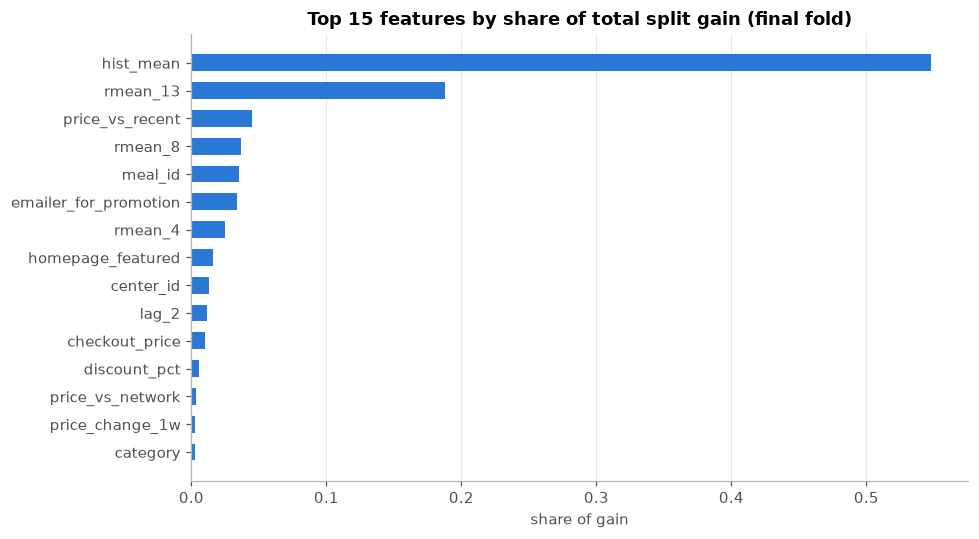

In [38]:
imp = pd.Series(last_model.feature_importance("gain"), index=FEATURES)
imp = (imp / imp.sum()).sort_values().tail(15)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(imp.index, imp.values, color=PALETTE[0], height=0.6)
ax.set_title("Top 15 features by share of total split gain (final fold)")
ax.set_xlabel("share of gain"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

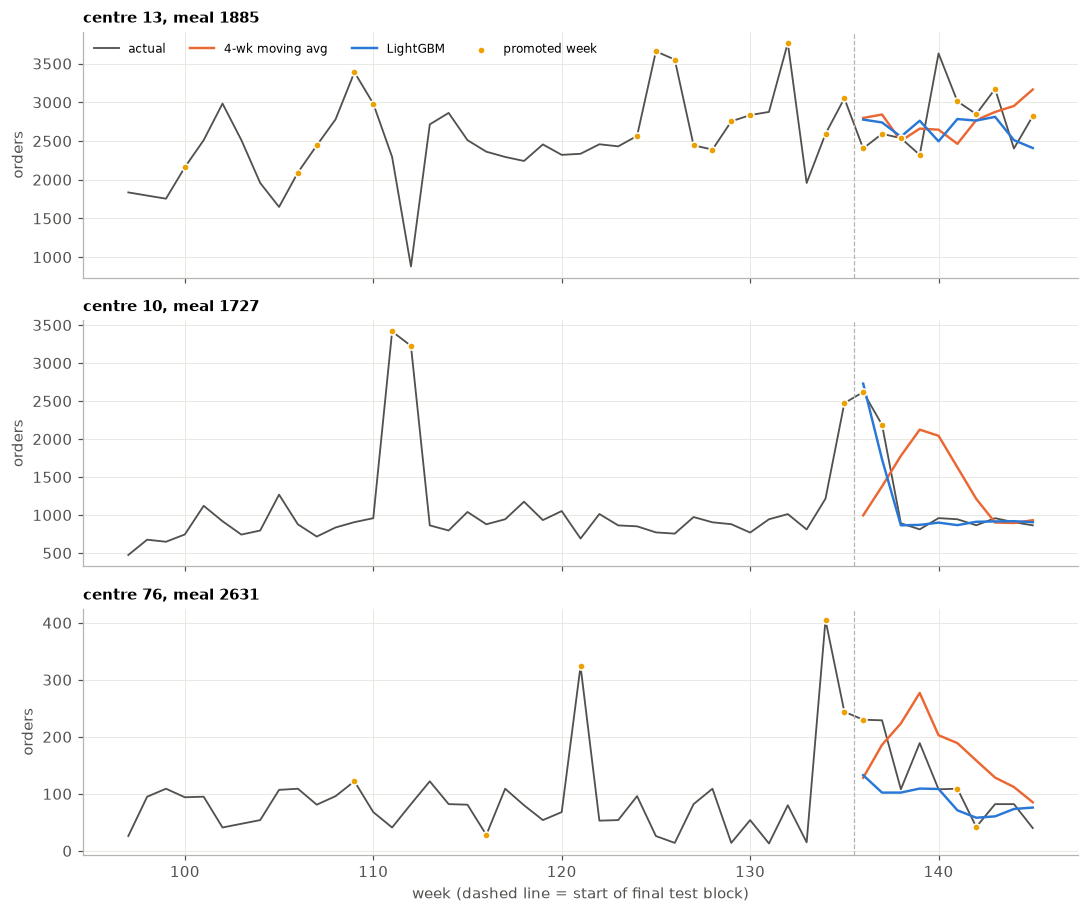

In [39]:
# Three example series from the final fold: highest-volume, a promoted one, and a mid-volume one.
lf = preds[preds.fold == N_FOLDS - 1]
vol = lf.groupby(["center_id", "meal_id"], observed=True).num_orders.sum().sort_values(ascending=False)
promoted = lf[lf.emailer_for_promotion == 1].groupby(["center_id", "meal_id"], observed=True).size().index
picks = [vol.index[0]]
picks += [k for k in vol.index if k in set(promoted) and k not in picks][:1]
picks += [vol.index[len(vol) // 2]]

fig, axes = plt.subplots(len(picks), 1, figsize=(10, 2.8 * len(picks)), sharex=True)
for ax, (c, m_id) in zip(np.atleast_1d(axes), picks):
    hist = pdf[(pdf.center_id == c) & (pdf.meal_id == m_id) & (pdf.week > last["test_start"] - 40)]
    p = lf[(lf.center_id == c) & (lf.meal_id == m_id)]
    ax.plot(hist.week, hist.num_orders, color="#52514e", lw=1.2, label="actual")
    ax.plot(p.week, p.pred_ma4, color=PALETTE[1], lw=1.6, label="4-wk moving avg")
    ax.plot(p.week, p.pred_lgb, color=PALETTE[0], lw=1.6, label="LightGBM")
    promo_wk = hist[(hist.emailer_for_promotion == 1) | (hist.homepage_featured == 1)].week
    ax.scatter(promo_wk, hist.set_index("week").loc[promo_wk, "num_orders"], s=22, color=PALETTE[3],
               zorder=3, label="promoted week", edgecolor="white", linewidth=1)
    ax.axvline(last["test_start"] - 0.5, color="#b5b4ae", lw=0.8, ls="--")
    ax.set_title(f"centre {c}, meal {m_id}", loc="left", fontsize=10); ax.set_ylabel("orders")
np.atleast_1d(axes)[0].legend(ncol=4, frameon=False, loc="upper left", fontsize=8)
np.atleast_1d(axes)[-1].set_xlabel("week (dashed line = start of final test block)")
plt.tight_layout(); plt.show()

## 9. Business impact: from forecast error to waste and stockouts

Forecast accuracy only matters through the decisions it drives. Here each forecast is treated as an **order quantity**: whatever is ordered above actual demand is waste, and whatever falls short is lost sales.

**Why a point forecast isn't the best order.** If a unit short costs `COST_UNDER` and a unit wasted costs `COST_OVER`, the order that minimises expected cost is the demand **quantile** at the *critical ratio*

$$q^* = \frac{c_{under}}{c_{under} + c_{over}}$$

(the newsvendor result). With the default assumptions (3 vs 1) that's the 75th percentile, so the business should deliberately order above the mean forecast. LightGBM's quantile objective estimates that percentile directly. Quantiles are unchanged by monotone transforms, so training on `log1p` and back-transforming gives the correct quantile of orders, with no smearing needed.

> The cost figures are **assumptions** set in the config cell. The useful outputs here are the *relative* comparisons and the unit counts. Before quoting money, replace the costs with real numbers from the business.

In [40]:
q_star = COST_UNDER / (COST_UNDER + COST_OVER)
print(f"critical ratio -> order at the {q_star:.0%} quantile of demand")

f = folds[-1]
train = pdf[pdf.week <= f["train_end"]]
q_params = {**LGB_PARAMS, "objective": "quantile", "alpha": q_star}
q_model, q_iter, _ = fit_lgb(train, q_params)

lf = preds[preds.fold == N_FOLDS - 1].copy()
lf["pred_lgb_q"] = np.expm1(q_model.predict(lf[FEATURES]))
print(f"quantile model: {q_iter} rounds; share of weeks where demand <= order: "
      f"{(lf.num_orders <= lf.pred_lgb_q).mean():.1%} (target {q_star:.0%})")

def inventory_outcome(name, y, order):
    over  = np.maximum(order - y, 0)
    under = np.maximum(y - order, 0)
    return dict(policy=name,
                units_wasted_per_wk=over.sum() / TEST_LEN,
                units_short_per_wk=under.sum() / TEST_LEN,
                fill_rate=1 - under.sum() / y.sum(),
                cost_per_wk=(COST_OVER * over.sum() + COST_UNDER * under.sum()) / TEST_LEN)

policies = {"naive": "pred_naive", "4-wk moving avg": "pred_ma4",
            "LightGBM (mean)": "pred_lgb", f"LightGBM (q{int(q_star * 100)})": "pred_lgb_q"}
biz = pd.DataFrame([inventory_outcome(k, lf.num_orders.values, lf[v].values) for k, v in policies.items()]
                   ).set_index("policy")
ref = biz.loc["4-wk moving avg", "cost_per_wk"]
biz["cost_vs_moving_avg"] = biz.cost_per_wk / ref - 1
display(biz.round(3))

critical ratio -> order at the 75% quantile of demand
quantile model: 315 rounds; share of weeks where demand <= order: 72.3% (target 75%)


,units_wasted_per_wk,units_short_per_wk,fill_rate,cost_per_wk,cost_vs_moving_avg
policy,,,,,
naive,190683.600,147825.100,0.802,634158.900,0.159
4-wk moving avg,172054.608,125005.267,0.832,547070.408,0.000
LightGBM (mean),127606.066,82363.125,0.890,374695.440,-0.315
LightGBM (q75),178202.430,53841.455,0.928,339726.796,-0.379


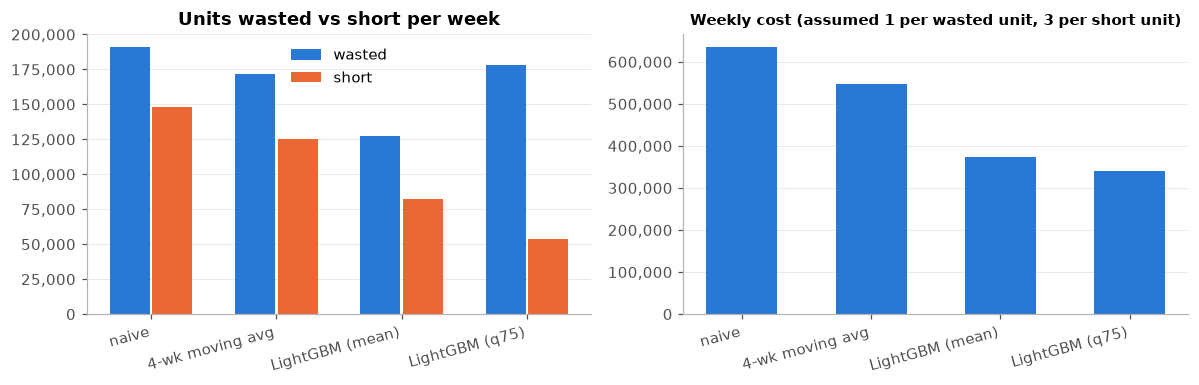

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.arange(len(biz))
axes[0].bar(x - 0.17, biz.units_wasted_per_wk, width=0.32, color=PALETTE[0], label="wasted")
axes[0].bar(x + 0.17, biz.units_short_per_wk, width=0.32, color=PALETTE[1], label="short")
axes[0].set_xticks(x); axes[0].set_xticklabels(biz.index, rotation=15, ha="right")
axes[0].set_title("Units wasted vs short per week"); axes[0].legend(frameon=False)
axes[0].grid(axis="x", visible=False)
axes[1].bar(x, biz.cost_per_wk, width=0.55, color=PALETTE[0])
axes[1].set_xticks(x); axes[1].set_xticklabels(biz.index, rotation=15, ha="right")
axes[1].set_title(f"Weekly cost (assumed {COST_OVER:g} per wasted unit, {COST_UNDER:g} per short unit)",
                  fontsize=10)
axes[1].grid(axis="x", visible=False)
for a in axes: a.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.tight_layout(); plt.show()

**Sensitivity to the cost assumption.** The ratio between the two costs is the number the business is least sure of, so the comparison is repeated across a range of ratios. If the quantile policy wins across the plausible range, the recommendation doesn't depend on getting that number exactly right.

In [42]:
rows = []
for ratio in [1, 2, 3, 5]:
    a = ratio / (ratio + 1)
    qm, _, _ = fit_lgb(train, {**LGB_PARAMS, "objective": "quantile", "alpha": a})
    q_pred = np.expm1(qm.predict(lf[FEATURES]))
    y = lf.num_orders.values
    def cost(order): return (np.maximum(order - y, 0).sum() + ratio * np.maximum(y - order, 0).sum()) / TEST_LEN
    rows.append(dict(under_to_over_cost=ratio, quantile=round(a, 2),
                     cost_ma4=cost(lf.pred_ma4.values), cost_lgb_mean=cost(lf.pred_lgb.values),
                     cost_lgb_quantile=cost(q_pred)))
sens = pd.DataFrame(rows)
sens["saving_vs_ma4"] = 1 - sens.cost_lgb_quantile / sens.cost_ma4
display(sens.round(3))

,under_to_over_cost,quantile,cost_ma4,cost_lgb_mean,cost_lgb_quantile,saving_vs_ma4
0,1,0.50,297059.875,209969.191,199928.448,0.327
1,2,0.67,422065.142,292332.316,283318.597,0.329
2,3,0.75,547070.408,374695.440,339726.796,0.379
3,5,0.83,797080.942,539421.690,412092.886,0.483


## 10. Findings

Generated from the results above, so the numbers stay correct when the notebook is re-run on new data.

In [43]:
def pct(x): return f"{x:.1%}"
b = biz
lines = [
    f"Backtest: {N_FOLDS} rolling folds of {TEST_LEN} weeks, forecasting {H} weeks ahead.",
    f"WAPE: naive {pct(res[res.model=='naive'].WAPE.mean())}, 4-wk moving average {pct(base_wape)}, "
    f"LightGBM {pct(lgb_wape)} ({pct((base_wape - lgb_wape) / base_wape)} lower than the moving average).",
    f"LightGBM bias after smearing correction: {res[res.model=='lgb'].bias.mean():+.1%} "
    f"(before correction: {res[res.model=='lgb_raw'].bias.mean():+.1%}).",
    f"Per-series exponential smoothing on the top-20 series: WAPE {pct(ets_tab.loc['ets','WAPE'])} "
    f"vs LightGBM {pct(ets_tab.loc['lgb','WAPE'])} on the same rows.",
    f"Ordering at the {q_star:.0%} quantile: fill rate {pct(b.iloc[-1].fill_rate)} vs "
    f"{pct(b.loc['4-wk moving avg','fill_rate'])} for the moving average, weekly cost "
    f"{b.iloc[-1].cost_vs_moving_avg:+.1%} relative to the moving average (under the stated cost assumptions).",
    f"Top 3 features by gain: {', '.join(imp.sort_values(ascending=False).index[:3])}.",
]
for l in lines: print("-", l)

- Backtest: 3 rolling folds of 10 weeks, forecasting 2 weeks ahead.
- WAPE: naive 51.7%, 4-wk moving average 45.8%, LightGBM 28.3% (38.3% lower than the moving average).
- LightGBM bias after smearing correction: -0.5% (before correction: -9.2%).
- Per-series exponential smoothing on the top-20 series: WAPE 13.5% vs LightGBM 15.8% on the same rows.
- Ordering at the 75% quantile: fill rate 92.8% vs 83.2% for the moving average, weekly cost -37.9% relative to the moving average (under the stated cost assumptions).
- Top 3 features by gain: hist_mean, rmean_13, price_vs_recent.


## 11. Limitations and recommendations

**Limitations**

* **Orders aren't demand.** The data records orders fulfilled. If a centre ran out, true demand was higher than recorded (censored demand), so the model learns to reproduce past shortfalls. Fixing this needs stock-out flags, which this dataset doesn't have.
* **Missing weeks are ambiguous.** They're treated as unknown. If they actually mean zero demand, the model overstates demand for intermittent series.
* **Costs are assumed.** The money comparison in section 9 is only as good as `COST_OVER` and `COST_UNDER`. The sensitivity table shows how much the conclusion depends on them.
* **One model per fold, no retraining inside the test block.** In production the model would be retrained weekly, which would likely improve later test weeks. The backtest is conservative on this point.
* **Spark at this size.** ~456k rows fit in pandas. Spark is used so the same feature pipeline scales unchanged to network-level data with daily granularity or many more SKUs; at this size it isn't faster.

In [44]:
preds.astype({"center_id": int, "meal_id": int}).to_csv(os.path.join(OUTPUT_DIR, "backtest_predictions.csv"), index=False)
res.to_csv(os.path.join(OUTPUT_DIR, "backtest_metrics.csv"), index=False)
biz.to_csv(os.path.join(OUTPUT_DIR, "inventory_outcomes.csv"))
last_model.save_model(os.path.join(OUTPUT_DIR, "lgb_point_model.txt"))
q_model.save_model(os.path.join(OUTPUT_DIR, "lgb_quantile_model.txt"))
print("saved to", OUTPUT_DIR, "->", sorted(os.listdir(OUTPUT_DIR)))

saved to outputs -> ['backtest_metrics.csv', 'backtest_predictions.csv', 'features.parquet', 'inventory_outcomes.csv', 'lgb_point_model.txt', 'lgb_quantile_model.txt']
